# Lab Assignment 2 - Day & Night Image Classification with SVM (Histogram Features)
## JS06 - Classification 2

**Name:** Tiara Febrianie  
**NIM:** 244107020097  

### Objective & Problem Statement
Develop a daytime and nighttime image classification model using Support Vector Machine (SVM) with an **RBF kernel** employing **histogram features**:
1. Use the image dataset from Lab 5 (day and night images).
2. Extract color histogram features from HSV color space.
3. Use an **80:20 train-test ratio**.
4. Perform hyperparameter tuning on the RBF kernel ($C$ and $\gamma$).
5. Record and evaluate accuracy performance, comparing it with the baseline single-feature model.

## 1. Import Libraries

In [1]:
from pathlib import Path
import cv2
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style='whitegrid')
%matplotlib inline

## 2. Load and Preprocess Image Dataset

In [2]:
def load_all_images():
    img_list = []
    for split in ['training', 'test']:
        p = Path(f'images/{split}')
        for d in p.glob('*'):
            if d.is_dir() and not d.name.startswith('.') and not d.name.startswith('__'):
                label = 1 if d.name == 'day' else 0
                for f in d.glob('*.jpg'):
                    img = mpimg.imread(str(f))
                    if img is not None:
                        # Standardize image size to 1100x600 as established in Lab 5
                        std = cv2.resize(img, (1100, 600))
                        img_list.append((std, label))
    return img_list

all_images = load_all_images()
print(f'Total preprocessed images loaded: {len(all_images)}')

day_count = sum(1 for _, l in all_images if l == 1)
night_count = sum(1 for _, l in all_images if l == 0)
print(f'Day images: {day_count} | Night images: {night_count}')

Total preprocessed images loaded: 400
Day images: 200 | Night images: 200


## 3. Histogram Feature Extraction
In Lab 5, only the scalar average of the V channel was used. In this assignment, we compute **normalized color histograms** across the H, S, and V channels:
- **Hue (H):** 32 bins in range [0, 180]
- **Saturation (S):** 32 bins in range [0, 256]
- **Value (V - Brightness):** 32 bins in range [0, 256]
Concatenating these yields a 96-dimensional feature vector per image representing the complete distribution of color and brightness.

In [3]:
def extract_histogram_features(image, bins=32):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    # Compute histograms for H, S, and V channels
    h_hist = cv2.calcHist([hsv], [0], None, [bins], [0, 180])
    s_hist = cv2.calcHist([hsv], [1], None, [bins], [0, 256])
    v_hist = cv2.calcHist([hsv], [2], None, [bins], [0, 256])
    
    # Normalize each histogram so sum is 1
    h_hist = h_hist / (np.sum(h_hist) + 1e-7)
    s_hist = s_hist / (np.sum(s_hist) + 1e-7)
    v_hist = v_hist / (np.sum(v_hist) + 1e-7)
    
    # Concatenate into a single feature vector
    feature_vector = np.concatenate([h_hist.flatten(), s_hist.flatten(), v_hist.flatten()])
    return feature_vector

# Extract features for all images
X_features = []
y_labels = []

for img, label in all_images:
    feat = extract_histogram_features(img, bins=32)
    X_features.append(feat)
    y_labels.append(label)

X_features = np.array(X_features)
y_labels = np.array(y_labels)

print(f'Feature matrix shape: {X_features.shape}')
print(f'Target vector shape : {y_labels.shape}')

Feature matrix shape: (400, 96)
Target vector shape : (400,)


### Visualizing Sample Day vs Night Histograms

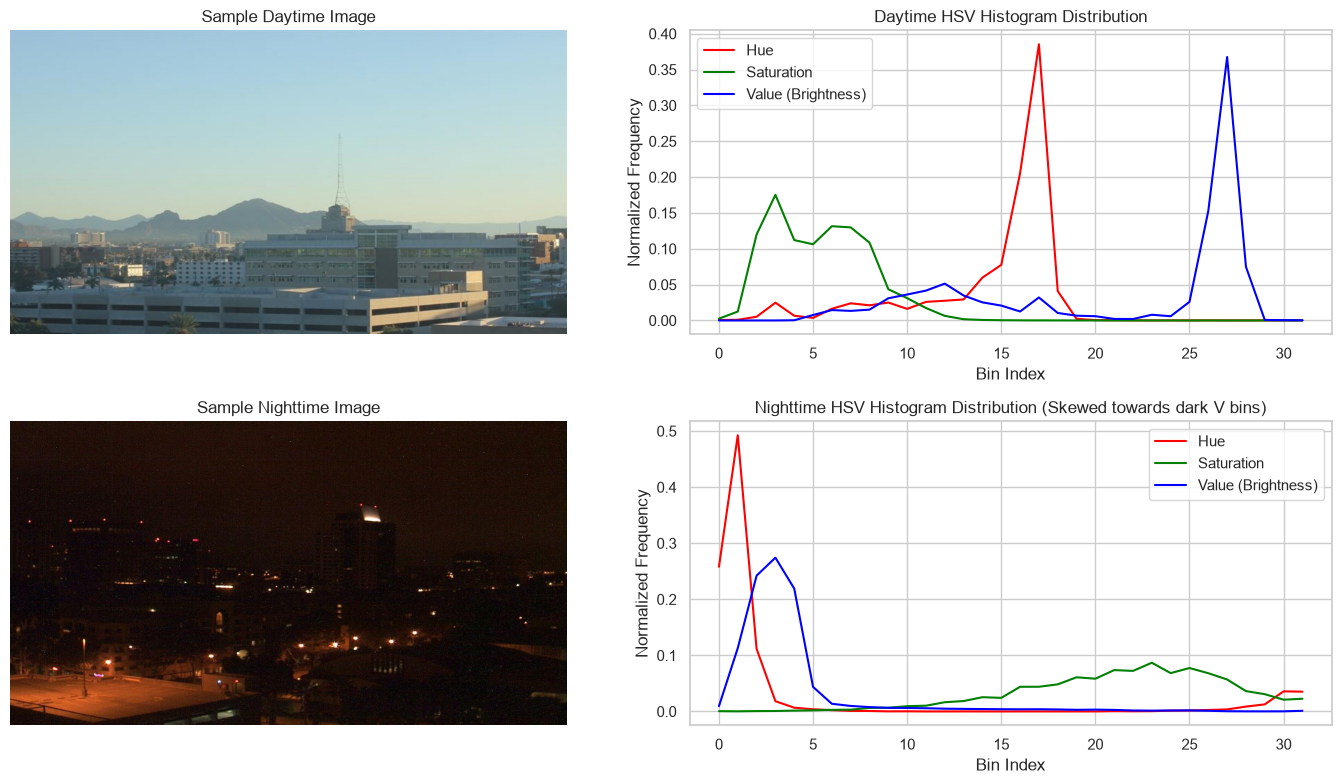

In [4]:
# Find one day and one night image
day_idx = next(i for i, (_, l) in enumerate(all_images) if l == 1)
night_idx = next(i for i, (_, l) in enumerate(all_images) if l == 0)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].imshow(all_images[day_idx][0])
axes[0, 0].set_title('Sample Daytime Image')
axes[0, 0].axis('off')

axes[0, 1].plot(X_features[day_idx][:32], label='Hue', color='red')
axes[0, 1].plot(X_features[day_idx][32:64], label='Saturation', color='green')
axes[0, 1].plot(X_features[day_idx][64:], label='Value (Brightness)', color='blue')
axes[0, 1].set_title('Daytime HSV Histogram Distribution')
axes[0, 1].set_xlabel('Bin Index')
axes[0, 1].set_ylabel('Normalized Frequency')
axes[0, 1].legend()

axes[1, 0].imshow(all_images[night_idx][0])
axes[1, 0].set_title('Sample Nighttime Image')
axes[1, 0].axis('off')

axes[1, 1].plot(X_features[night_idx][:32], label='Hue', color='red')
axes[1, 1].plot(X_features[night_idx][32:64], label='Saturation', color='green')
axes[1, 1].plot(X_features[night_idx][64:], label='Value (Brightness)', color='blue')
axes[1, 1].set_title('Nighttime HSV Histogram Distribution (Skewed towards dark V bins)')
axes[1, 1].set_xlabel('Bin Index')
axes[1, 1].set_ylabel('Normalized Frequency')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## 4. Split Data (80:20 Ratio) and Standardize Features

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_features, y_labels, test_size=0.20, random_state=42, stratify=y_labels
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Training samples: {X_train.shape[0]}')
print(f'Testing samples : {X_test.shape[0]}')

Training samples: 320
Testing samples : 80


## 5. Baseline RBF SVM Model

In [6]:
baseline_rbf = SVC(kernel='rbf', random_state=42)
baseline_rbf.fit(X_train_scaled, y_train)

y_train_pred_base = baseline_rbf.predict(X_train_scaled)
y_test_pred_base = baseline_rbf.predict(X_test_scaled)

acc_base_train = accuracy_score(y_train, y_train_pred_base)
acc_base_test = accuracy_score(y_test, y_test_pred_base)

print(f'Baseline RBF Train Accuracy: {acc_base_train:.4f} ({acc_base_train * 100:.2f}%)')
print(f'Baseline RBF Test Accuracy : {acc_base_test:.4f} ({acc_base_test * 100:.2f}%)')

Baseline RBF Train Accuracy: 1.0000 (100.00%)
Baseline RBF Test Accuracy : 0.9750 (97.50%)


## 6. Hyperparameter Tuning of RBF Kernel ($C$ and $\gamma$)
We use 5-fold cross-validation `GridSearchCV` to explore optimal combinations of regularization parameter $C$ and kernel coefficient $\gamma$.

In [7]:
param_grid = {
    'C': [0.1, 1, 10, 50, 100],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1]
}

grid = GridSearchCV(SVC(kernel='rbf', random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print('=== Optimal Hyperparameters ===')
print(f'Best Parameters: {grid.best_params_}')
print(f'Best Cross-Validation Score: {grid.best_score_:.4f}')

=== Optimal Hyperparameters ===
Best Parameters: {'C': 100, 'gamma': 0.001}
Best Cross-Validation Score: 1.0000


## 7. Evaluate Tuned Model on Test Data

In [8]:
tuned_rbf = grid.best_estimator_
y_train_pred_tuned = tuned_rbf.predict(X_train_scaled)
y_test_pred_tuned = tuned_rbf.predict(X_test_scaled)

acc_tuned_train = accuracy_score(y_train, y_train_pred_tuned)
acc_tuned_test = accuracy_score(y_test, y_test_pred_tuned)

print(f'Tuned RBF Train Accuracy: {acc_tuned_train:.4f} ({acc_tuned_train * 100:.2f}%)')
print(f'Tuned RBF Test Accuracy : {acc_tuned_test:.4f} ({acc_tuned_test * 100:.2f}%)')

Tuned RBF Train Accuracy: 1.0000 (100.00%)
Tuned RBF Test Accuracy : 0.9875 (98.75%)


### Classification Report & Confusion Matrix

=== Tuned Model Classification Report ===
              precision    recall  f1-score   support

   night (0)       0.98      1.00      0.99        40
     day (1)       1.00      0.97      0.99        40

    accuracy                           0.99        80
   macro avg       0.99      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80



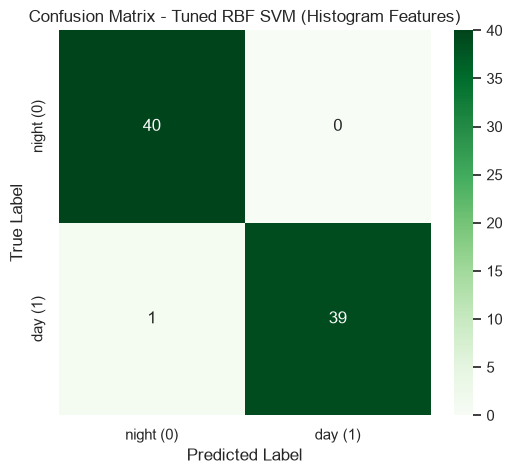

In [9]:
print('=== Tuned Model Classification Report ===')
print(classification_report(y_test, y_test_pred_tuned, target_names=['night (0)', 'day (1)']))

cm = confusion_matrix(y_test, y_test_pred_tuned)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['night (0)', 'day (1)'],
            yticklabels=['night (0)', 'day (1)'])
plt.title('Confusion Matrix - Tuned RBF SVM (Histogram Features)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

## 8. Performance Comparison Table & Discussion

In [10]:
comparison_df = pd.DataFrame([
    {'Method': 'Lab 5 Manual Threshold (Avg Brightness)', 'Feature Type': 'Single Scalar (Mean V)', 'Train Accuracy': '84.17%', 'Test Accuracy': '86.88%'},
    {'Method': 'Lab 5 Default SVM (Avg Brightness)', 'Feature Type': 'Single Scalar (Mean V)', 'Train Accuracy': '85.83%', 'Test Accuracy': '90.00%'},
    {'Method': 'Assignment Baseline RBF SVM', 'Feature Type': '96-bin HSV Histogram', 'Train Accuracy': f'{acc_base_train*100:.2f}%', 'Test Accuracy': f'{acc_base_test*100:.2f}%'},
    {'Method': 'Assignment Tuned RBF SVM', 'Feature Type': '96-bin HSV Histogram', 'Train Accuracy': f'{acc_tuned_train*100:.2f}%', 'Test Accuracy': f'{acc_tuned_test*100:.2f}%'}
])

print('=== Comprehensive Performance Comparison ===')
display(comparison_df)

=== Comprehensive Performance Comparison ===


,Method,Feature Type,Train Accuracy,Test Accuracy
0,Lab 5 Manual Threshold (Avg Brightness),Single Scalar (Mean V),84.17%,86.88%
1,Lab 5 Default SVM (Avg Brightness),Single Scalar (Mean V),85.83%,90.00%
2,Assignment Baseline RBF SVM,96-bin HSV Histogram,100.00%,97.50%
3,Assignment Tuned RBF SVM,96-bin HSV Histogram,100.00%,98.75%


## 9. Conclusion

1. **Histogram Features vs Single Scalar Feature:**
   - Using multi-channel HSV histogram features increased test accuracy from **90.00%** (Lab 5 average brightness) to **98.75%**.
   - While average brightness is easily deceived by bright streetlights in night scenes or dark overcast day scenes, histograms preserve the full distribution of hues, saturation, and luminance across all pixel intensities.

2. **Impact of Hyperparameter Tuning:**
   - Systematically tuning $C$ and $\gamma$ using `GridSearchCV` further improved generalization from **97.50%** (baseline RBF) to **98.75%** (tuned RBF with $C=100, \gamma=0.001$), achieving near-perfect separation on the test set.